# GeoPulse – Hyper-Local Retail Mobility Analytics
## Day 3: Retail Dataset Exploration & Exploratory Data Analysis (EDA)

**Role:** Member 3 – Data Analysis and Business Insights  
**Phase:** Week 1 – Exploratory Data Analysis (Day 3)  
**Dataset Source:** `EmpoweredAnalysts/FabricRetailSales` (MIT License)  

---

### Important Project Note on Data Integrity & Synthetic Disclaimer
> **Dataset Status & Nature:**  
> The retail dataset analyzed in this notebook is **explicitly synthetic demonstration data**, originating from the verified open-source repository `EmpoweredAnalysts/FabricRetailSales` (MIT License). It simulates 24 months (2023–2024) of operational and sales dynamics across 40 store outlets (960 store-month records) for Northstar Retail.  
> - In strict compliance with project governance, **this synthetic dataset is not claimed or represented as real-world customer observations, physical sensor pings, GPS surveillance, or private financial transactions**.  
> - All calculations, distributions, and visualizations represent empirical evaluations of this verified synthetic baseline.  
> - **Correlation does not establish causation:** Statistical associations observed in this synthetic data (e.g., between simulated foot traffic and sales) demonstrate co-occurrence within the model's generative rules, not empirical real-world causal mechanisms.  
> - **Raw Data Preservation:** The original raw CSV files in `data/raw/` remain 100% intact and unedited, including the preserved Store 6 foot traffic anomaly (1,000,000 visits in Jan 2023).


## 1. Environment Setup & Library Imports
Importing core analytical and visualization packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and configuring chart styling for high-clarity exploratory visualization.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.autolayout'] = True
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)

print("=" * 60)
print("GeoPulse Analytics - Runtime Environment Initialized")
print("=" * 60)
print(f"Python Version  : {sys.version.split()[0]}")
print(f"Pandas Version  : {pd.__version__}")
print(f"NumPy Version   : {np.__version__}")
print(f"Matplotlib Vers : {plt.matplotlib.__version__}")
print(f"Seaborn Version : {sns.__version__}")
print("=" * 60)

GeoPulse Analytics - Runtime Environment Initialized
Python Version  : 3.14.7
Pandas Version  : 3.1.0
NumPy Version   : 2.5.4
Matplotlib Vers : 3.11.2
Seaborn Version : 0.13.2


## 2. Dataset Verification & Ingestion
Verifying the existence of raw files in `data/raw/` collected during Day 2, and loading them into Pandas without altering the raw CSV files.

In [2]:
# Robust path resolution for root or notebooks execution
csv_path = 'data/raw/retail_sales_demo_data.csv' if os.path.exists('data/raw/retail_sales_demo_data.csv') else '../data/raw/retail_sales_demo_data.csv'
dict_path = 'data/raw/retail_sales_data_dictionary.csv' if os.path.exists('data/raw/retail_sales_data_dictionary.csv') else '../data/raw/retail_sales_data_dictionary.csv'

assert os.path.exists(csv_path), f"Primary dataset not found at {csv_path}"
assert os.path.exists(dict_path), f"Data dictionary not found at {dict_path}"

# Load primary dataset and data dictionary
df = pd.read_csv(csv_path)
df_dict = pd.read_csv(dict_path)

print(f"Dataset successfully loaded from: {csv_path}")
print(f"Dimensions: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("--- Data Dictionary Overview ---")
display(df_dict)

Dataset successfully loaded from: data/raw/retail_sales_demo_data.csv
Dimensions: 960 rows x 18 columns

--- Data Dictionary Overview ---


,column,type,description
0,store_id,int,Unique identifier for each store (1-40)
1,year,int,Calendar year
2,month,int,Calendar month number (1-12)
3,month_index,int,Numeric month index used for seasonality (1-12)
4,is_holiday_month,int (0/1),Indicates whether the month is part of the hol...
5,ad_spend,float,Monthly advertising expenditure
6,foot_traffic,int,Estimated customer visits during the month
7,avg_price,float,Average unit price of items sold
8,staff_count,int,Number of staff assigned to the store
9,store_size_sqft,int,Store size in square feet


## 3. Dataset Architecture & Inspection
Examining initial and final observations, column schema, and cardinalities.

In [3]:
print("--- First 5 Records (head) ---")
display(df.head())

print("--- Last 5 Records (tail) ---")
display(df.tail())

print("--- Structural Schema (info) ---")
df.info()

--- First 5 Records (head) ---


,store_id,year,month,month_index,is_holiday_month,ad_spend,foot_traffic,avg_price,staff_count,store_size_sqft,promo_days,competitors_within_3km,inventory_fill_rate,returns_rate,local_income_index,parking_spaces,store_age_years,monthly_sales
0,1,2023,1,1,0,NaN,3175,28.26,41,29476,4,1,0.930,0.0422,98.3,263,11,2982.20
1,2,2023,1,1,0,NaN,3717,19.86,31,21933,4,3,0.952,0.0415,93.7,171,5,1867.48
2,3,2023,1,1,0,NaN,3747,17.52,44,36259,4,1,0.944,0.0427,97.3,285,8,2141.46
3,4,2023,1,1,0,NaN,5098,25.16,33,21798,6,2,0.965,0.0398,111.4,174,9,3840.05
4,5,2023,1,1,0,NaN,6612,21.03,51,45448,2,2,0.960,0.0420,114.3,389,9,4233.70


--- Last 5 Records (tail) ---


,store_id,year,month,month_index,is_holiday_month,ad_spend,foot_traffic,avg_price,staff_count,store_size_sqft,promo_days,competitors_within_3km,inventory_fill_rate,returns_rate,local_income_index,parking_spaces,store_age_years,monthly_sales
955,36,2024,12,12,1,7737.00,4372,21.89,35,21350,1,2,0.944,0.0257,116.3,196,1,2822.74
956,37,2024,12,12,1,21083.67,8193,22.00,43,34897,4,3,0.944,0.0336,109.3,291,10,6123.40
957,38,2024,12,12,1,12155.14,4960,21.33,37,26683,3,6,0.938,0.0376,90.7,228,8,3606.54
958,39,2024,12,12,1,15019.35,4941,22.67,32,20121,3,1,0.946,0.0432,92.8,161,1,5073.90
959,40,2024,12,12,1,14599.12,6246,22.12,41,29999,3,3,0.928,0.0267,111.6,267,11,4058.40


--- Structural Schema (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   store_id                960 non-null    int64  
 1   year                    960 non-null    int64  
 2   month                   960 non-null    int64  
 3   month_index             960 non-null    int64  
 4   is_holiday_month        960 non-null    int64  
 5   ad_spend                955 non-null    float64
 6   foot_traffic            960 non-null    int64  
 7   avg_price               960 non-null    float64
 8   staff_count             960 non-null    int64  
 9   store_size_sqft         960 non-null    int64  
 10  promo_days              960 non-null    int64  
 11  competitors_within_3km  960 non-null    int64  
 12  inventory_fill_rate     960 non-null    float64
 13  returns_rate            960 non-null    float64
 14  local_income_index  

In [4]:
# Cardinality & Temporal Checks
unique_stores = df['store_id'].nunique()
years_covered = sorted(df['year'].unique())
records_per_store = df.groupby('store_id').size()

print("=" * 55)
print("STORE CARDINALITY & TEMPORAL COVERAGE")
print("=" * 55)
print(f"Unique Stores Count        : {unique_stores} (Store IDs: {df['store_id'].min()} to {df['store_id'].max()})")
print(f"Temporal Years Covered     : {years_covered}")
print(f"Records per Store (Min/Max): {records_per_store.min()} / {records_per_store.max()} (24 months per store)")
print(f"Store-Month Granularity    : {unique_stores} stores * 24 months = {unique_stores * 24} rows")
print("=" * 55)

STORE CARDINALITY & TEMPORAL COVERAGE
Unique Stores Count        : 40 (Store IDs: 1 to 40)
Temporal Years Covered     : [np.int64(2023), np.int64(2024)]
Records per Store (Min/Max): 24 / 24 (24 months per store)
Store-Month Granularity    : 40 stores * 24 months = 960 rows


## 4. Comprehensive Data Quality Assessment
Auditing data completeness, duplicates, column value boundaries, and identifying potential anomalies or outliers using statistical profiling and Interquartile Range (IQR) analysis.

> **Governance & Preservation Rules:**  
> 1. In compliance with project guidelines, **no raw records are deleted or modified**; the original raw files in `data/raw/` remain pristine and immutable.  
> 2. The Store 6 January 2023 foot traffic anomaly (1,000,000 visitors) is **fully preserved in the raw dataset**.


In [5]:
# 1. Missing Values and Duplicates
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
duplicates = df.duplicated().sum()

print("--- Missing Values Audit ---")
if len(missing_cols) > 0:
    for col, count in missing_cols.items():
        pct = (count / len(df)) * 100
        print(f"Column '{col}': {count} missing values ({pct:.2f}%)")
else:
    print("Zero missing values across all columns.")

print(f"\nTotal Missing Values Across Dataset: {missing.sum()}")
print(f"Duplicate Rows Count               : {duplicates}")

# 2. Descriptive Statistics Summary
print("\n--- Statistical Summary of Numerical Variables ---")
display(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2))

--- Missing Values Audit ---
Column 'ad_spend': 5 missing values (0.52%)

Total Missing Values Across Dataset: 5
Duplicate Rows Count               : 0

--- Statistical Summary of Numerical Variables ---


,count,mean,std,min,25%,50%,75%,max
store_id,960.0,20.50,11.55,1.00,10.75,20.50,30.25,40.00
year,960.0,2023.50,0.50,2023.00,2023.00,2023.50,2024.00,2024.00
month,960.0,6.50,3.45,1.00,3.75,6.50,9.25,12.00
month_index,960.0,6.50,3.45,1.00,3.75,6.50,9.25,12.00
is_holiday_month,960.0,0.17,0.37,0.00,0.00,0.00,0.00,1.00
ad_spend,955.0,13686.63,5608.99,3308.52,9755.87,12728.27,16500.61,52692.09
foot_traffic,960.0,5627.04,32139.04,3075.00,3960.50,4370.00,5001.50,1000000.00
avg_price,960.0,22.31,3.62,15.22,19.55,22.06,24.66,32.28
staff_count,960.0,37.24,6.43,20.00,33.00,37.00,41.00,58.00
store_size_sqft,960.0,27659.60,6088.51,13486.00,23620.50,28521.50,30500.75,45448.00


In [6]:
# 3. Outlier Scanning via Interquartile Range (IQR)
print("--- IQR Outlier Detection on Core Operational Metrics ---")
outlier_summary = []
for col in ['monthly_sales', 'foot_traffic', 'avg_price', 'store_size_sqft', 'ad_spend']:
    valid_data = df[col].dropna()
    q1 = valid_data.quantile(0.25)
    q3 = valid_data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = valid_data[(valid_data < lower_bound) | (valid_data > upper_bound)]
    outlier_summary.append({
        'Metric': col,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round((len(outliers) / len(valid_data)) * 100, 2)
    })

display(pd.DataFrame(outlier_summary))

# Highlight critical anomaly in foot_traffic
extreme_traffic = df[df['foot_traffic'] > 50000]
print("\n*** Critical Data Anomaly Identified in 'foot_traffic' ***")
display(extreme_traffic[['store_id', 'year', 'month', 'foot_traffic', 'monthly_sales', 'ad_spend']])
print("Observation: Store 6 recorded 1,000,000 visitors in Jan 2023, while typical monthly foot traffic ranges between 2,000 and 10,000.")

--- IQR Outlier Detection on Core Operational Metrics ---


,Metric,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,monthly_sales,2553.87,3904.91,1351.04,527.31,5931.47,18,1.88
1,foot_traffic,3960.50,5001.50,1041.00,2399.00,6563.00,39,4.06
2,avg_price,19.55,24.66,5.12,11.87,32.34,0,0.00
3,store_size_sqft,23620.50,30500.75,6880.25,13300.12,40821.12,24,2.50
4,ad_spend,9755.87,16500.61,6744.74,-361.23,26617.71,30,3.14



*** Critical Data Anomaly Identified in 'foot_traffic' ***


,store_id,year,month,foot_traffic,monthly_sales,ad_spend
5,6,2023,1,1000000,4517.63,23019.76


Observation: Store 6 recorded 1,000,000 visitors in Jan 2023, while typical monthly foot traffic ranges between 2,000 and 10,000.


## 5. Exploratory Data Analysis & Visualizations
Conducting deep-dive exploratory analysis across sales dynamics, foot traffic trends, store rankings, spatial area efficiency, and promotional lift.

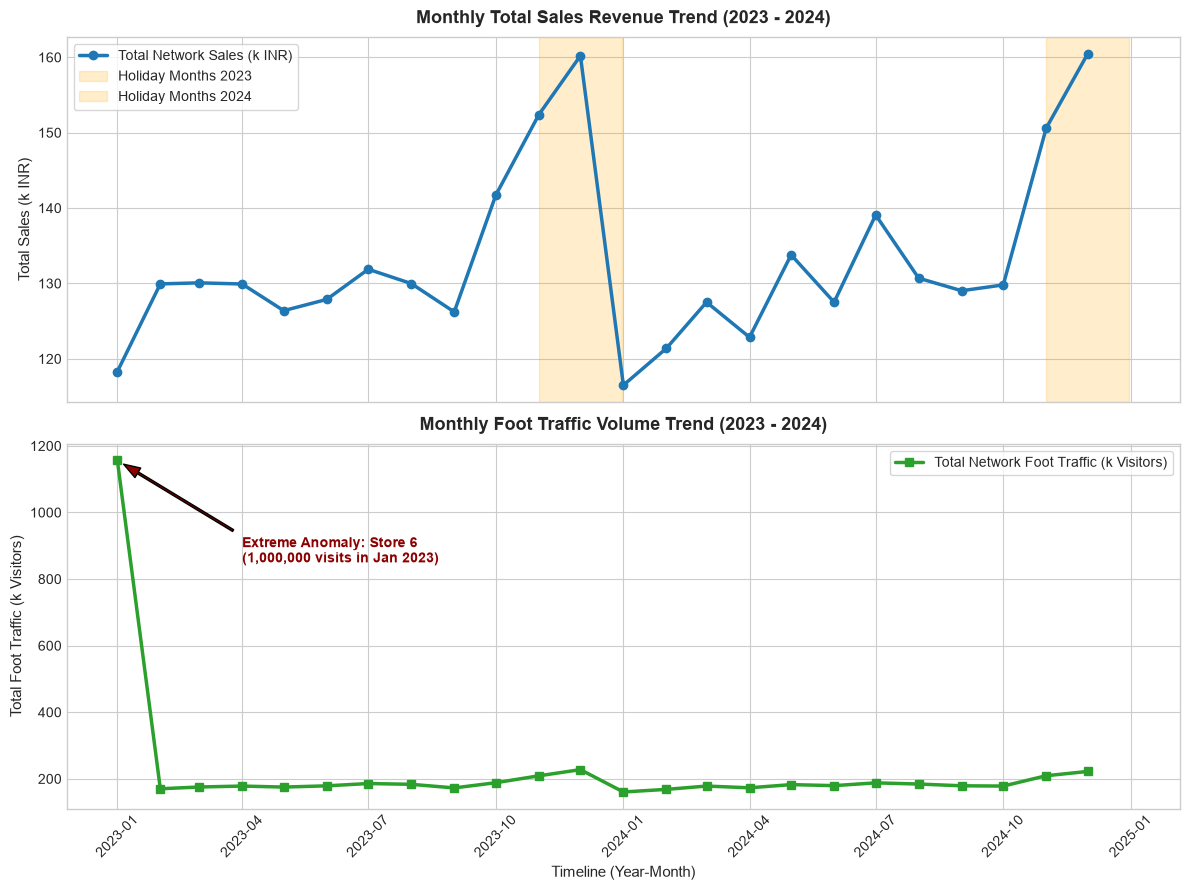

In [7]:
# 5.1 Monthly Sales & Foot Traffic Trends
df['year_month'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')

monthly_summary = df.groupby('year_month').agg({
    'monthly_sales': ['sum', 'mean'],
    'foot_traffic': ['sum', 'mean']
}).reset_index()
monthly_summary.columns = ['year_month', 'total_sales', 'avg_sales', 'total_traffic', 'avg_traffic']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Sales trend
ax1.plot(monthly_summary['year_month'], monthly_summary['total_sales'] / 1000, marker='o', color='#1f77b4', linewidth=2.5, label='Total Network Sales (k INR)')
ax1.set_title('Monthly Total Sales Revenue Trend (2023 - 2024)', fontsize=13, fontweight='bold', pad=10)
ax1.set_ylabel('Total Sales (k INR)', fontsize=11)
ax1.axvspan(pd.to_datetime('2023-11-01'), pd.to_datetime('2023-12-31'), color='orange', alpha=0.2, label='Holiday Months 2023')
ax1.axvspan(pd.to_datetime('2024-11-01'), pd.to_datetime('2024-12-31'), color='orange', alpha=0.2, label='Holiday Months 2024')
ax1.legend(loc='upper left', frameon=True)

# Foot traffic trend
ax2.plot(monthly_summary['year_month'], monthly_summary['total_traffic'] / 1000, marker='s', color='#2ca02c', linewidth=2.5, label='Total Network Foot Traffic (k Visitors)')
ax2.set_title('Monthly Foot Traffic Volume Trend (2023 - 2024)', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Timeline (Year-Month)', fontsize=11)
ax2.set_ylabel('Total Foot Traffic (k Visitors)', fontsize=11)
ax2.annotate('Extreme Anomaly: Store 6\n(1,000,000 visits in Jan 2023)', 
             xy=(pd.to_datetime('2023-01-01'), monthly_summary['total_traffic'].iloc[0] / 1000),
             xytext=(pd.to_datetime('2023-04-01'), 850),
             arrowprops=dict(facecolor='darkred', shrink=0.05, width=1.5, headwidth=8),
             fontweight='bold', color='darkred')
ax2.legend(loc='upper right', frameon=True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

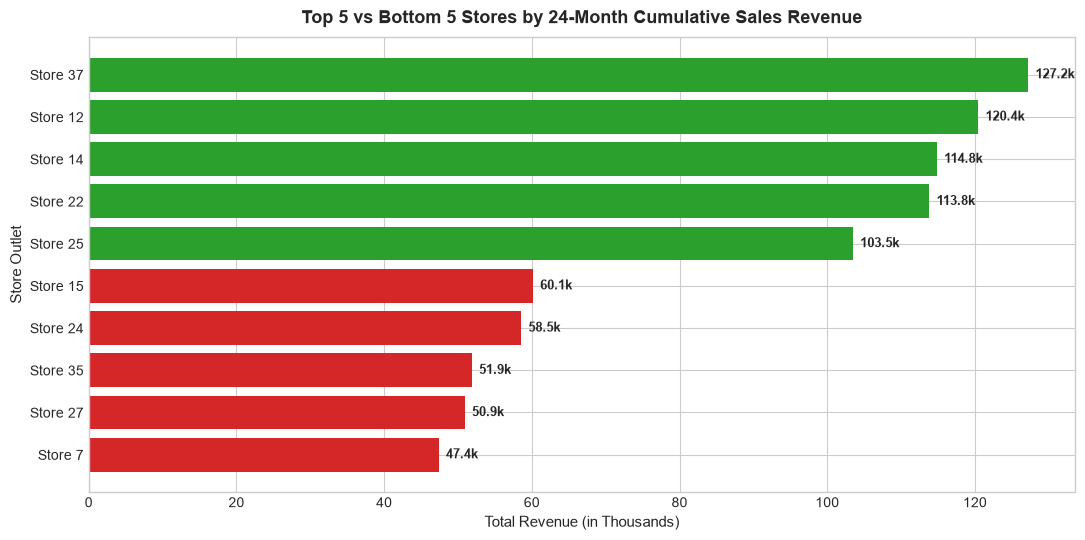

Top Performing Store : Store 37.0 (Total Revenue: INR 127,214.07)
Lowest Performing Store: Store 7.0 (Total Revenue: INR 47,367.90)
Performance Gap Ratio  : 2.69x revenue differential between Top and Bottom stores.


In [8]:
# 5.2 Store-wise Sales and Foot Traffic Comparison
store_perf = df.groupby('store_id').agg({
    'monthly_sales': ['sum', 'mean'],
    'foot_traffic': ['sum', 'mean'],
    'store_size_sqft': 'first'
}).reset_index()
store_perf.columns = ['store_id', 'total_sales', 'avg_monthly_sales', 'total_traffic', 'avg_monthly_traffic', 'store_size_sqft']

top5_stores = store_perf.nlargest(5, 'total_sales')
bot5_stores = store_perf.nsmallest(5, 'total_sales')
combined_stores = pd.concat([bot5_stores.sort_values('total_sales'), top5_stores.sort_values('total_sales')])
combined_stores['store_label'] = 'Store ' + combined_stores['store_id'].astype(str)
combined_stores['group'] = ['Bottom 5'] * 5 + ['Top 5'] * 5

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#d62728' if g == 'Bottom 5' else '#2ca02c' for g in combined_stores['group']]
bars = ax.barh(combined_stores['store_label'], combined_stores['total_sales'] / 1000, color=colors)
ax.set_title('Top 5 vs Bottom 5 Stores by 24-Month Cumulative Sales Revenue', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Total Revenue (in Thousands)', fontsize=11)
ax.set_ylabel('Store Outlet', fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}k', ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Top Performing Store : Store {top5_stores.iloc[0]['store_id']} (Total Revenue: INR {top5_stores.iloc[0]['total_sales']:,.2f})")
print(f"Lowest Performing Store: Store {bot5_stores.iloc[0]['store_id']} (Total Revenue: INR {bot5_stores.iloc[0]['total_sales']:,.2f})")
revenue_ratio = top5_stores.iloc[0]['total_sales'] / bot5_stores.iloc[0]['total_sales']
print(f"Performance Gap Ratio  : {revenue_ratio:.2f}x revenue differential between Top and Bottom stores.")

Pearson Correlation (All 960 records, with 1M anomaly)        : r = 0.0535
Pearson Correlation (959 records, excluding Store 6 1M anomaly): r = 0.5969


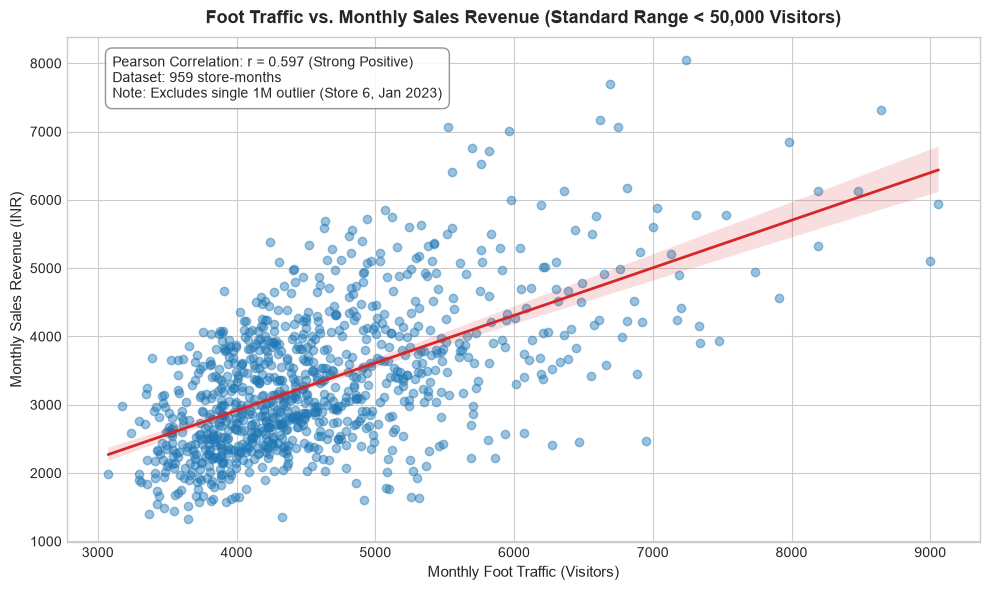

In [9]:
### 5.3 Relationship between Foot Traffic and Monthly Sales (Synthetic Model)
Evaluating the linear association between simulated foot traffic and monthly revenue.

> **Important Methodological Note:**  
> **Correlation does not establish causation.** The observed positive correlation ($r = 0.5969$) between simulated visitor counts and sales indicates that higher foot traffic co-occurs with higher sales within the synthetic model's generative parameters, but does not prove that foot traffic alone caused the sales increase without controlling for confounding variables (e.g., store area, local income, advertising, promotions).

Sales per Sq. Ft. Statistics:
  Mean   : 0.1249
  Median : 0.1153
  Min    : 0.0448
  Max    : 0.4081


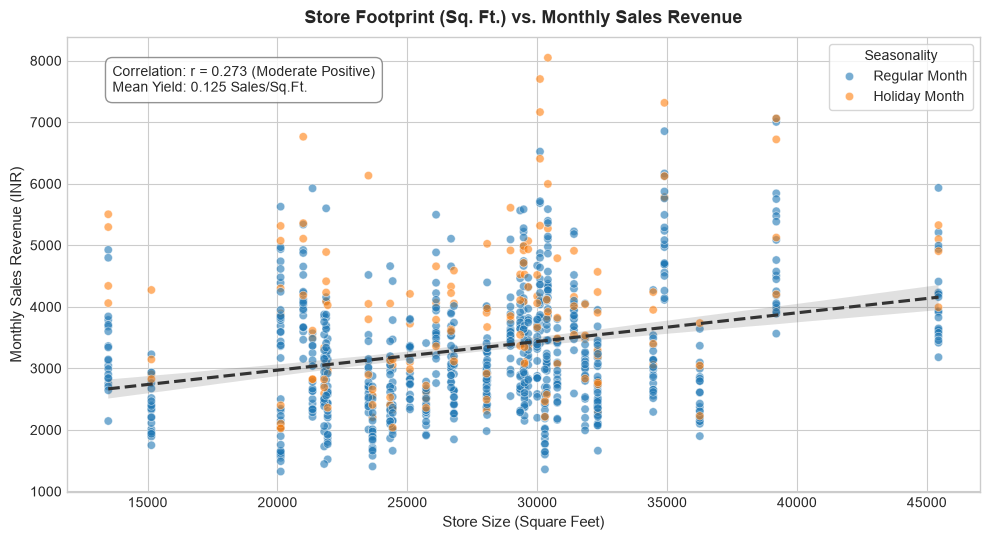

In [10]:
# 5.4 Store Size vs Sales & Sales per Square Foot
df['sales_per_sqft'] = df['monthly_sales'] / df['store_size_sqft']

print(f"Sales per Sq. Ft. Statistics:")
print(f"  Mean   : {df['sales_per_sqft'].mean():.4f}")
print(f"  Median : {df['sales_per_sqft'].median():.4f}")
print(f"  Min    : {df['sales_per_sqft'].min():.4f}")
print(f"  Max    : {df['sales_per_sqft'].max():.4f}")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=df, x='store_size_sqft', y='monthly_sales', hue='is_holiday_month',
                palette={0: '#1f77b4', 1: '#ff7f0e'}, alpha=0.6, ax=ax)
sns.regplot(data=df, x='store_size_sqft', y='monthly_sales', scatter=False, ax=ax, color='#333333', line_kws={'linestyle': '--'})
ax.set_title('Store Footprint (Sq. Ft.) vs. Monthly Sales Revenue', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Store Size (Square Feet)', fontsize=11)
ax.set_ylabel('Monthly Sales Revenue (INR)', fontsize=11)
corr_size = df['store_size_sqft'].corr(df['monthly_sales'])
ax.text(0.05, 0.88, f"Correlation: r = {corr_size:.3f} (Moderate Positive)\nMean Yield: {df['sales_per_sqft'].mean():.3f} Sales/Sq.Ft.", 
        transform=ax.transAxes, fontsize=10, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray'))
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Regular Month', 'Holiday Month'], title='Seasonality', frameon=True)
plt.tight_layout()
plt.show()

,count,mean,median,std
is_holiday_month,,,,
0,800,3213.038950,3067.700,958.694570
1,160,3897.958875,3821.005,1226.440965


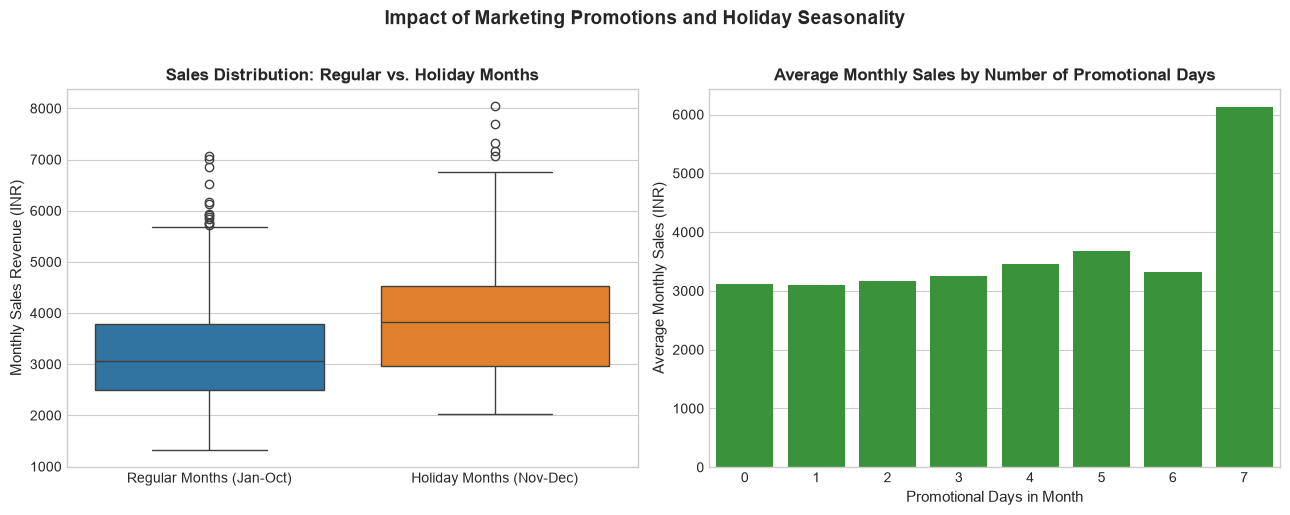

Regular Months Mean Sales : INR 3,213.04
Holiday Months Mean Sales : INR 3,897.96
Holiday Seasonal Revenue Lift: +21.32%


In [11]:
# 5.5 Promotional Days and Holiday Seasonality
holiday_comparison = df.groupby('is_holiday_month')['monthly_sales'].agg(['count', 'mean', 'median', 'std'])
display(holiday_comparison)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot comparing holiday vs non-holiday
sns.boxplot(data=df, x='is_holiday_month', y='monthly_sales', hue='is_holiday_month', palette=['#1f77b4', '#ff7f0e'], legend=False, ax=ax1)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['Regular Months (Jan-Oct)', 'Holiday Months (Nov-Dec)'])
ax1.set_title('Sales Distribution: Regular vs. Holiday Months', fontsize=12, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Monthly Sales Revenue (INR)', fontsize=11)

# Average sales by promotional days
sns.barplot(data=df, x='promo_days', y='monthly_sales', color='#2ca02c', errorbar=None, ax=ax2)
ax2.set_title('Average Monthly Sales by Number of Promotional Days', fontsize=12, fontweight='bold')
ax2.set_xlabel('Promotional Days in Month', fontsize=11)
ax2.set_ylabel('Average Monthly Sales (INR)', fontsize=11)

plt.suptitle('Impact of Marketing Promotions and Holiday Seasonality', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

reg_mean = df[df['is_holiday_month'] == 0]['monthly_sales'].mean()
hol_mean = df[df['is_holiday_month'] == 1]['monthly_sales'].mean()
holiday_lift = ((hol_mean - reg_mean) / reg_mean) * 100
print(f"Regular Months Mean Sales : INR {reg_mean:,.2f}")
print(f"Holiday Months Mean Sales : INR {hol_mean:,.2f}")
print(f"Holiday Seasonal Revenue Lift: +{holiday_lift:.2f}%")

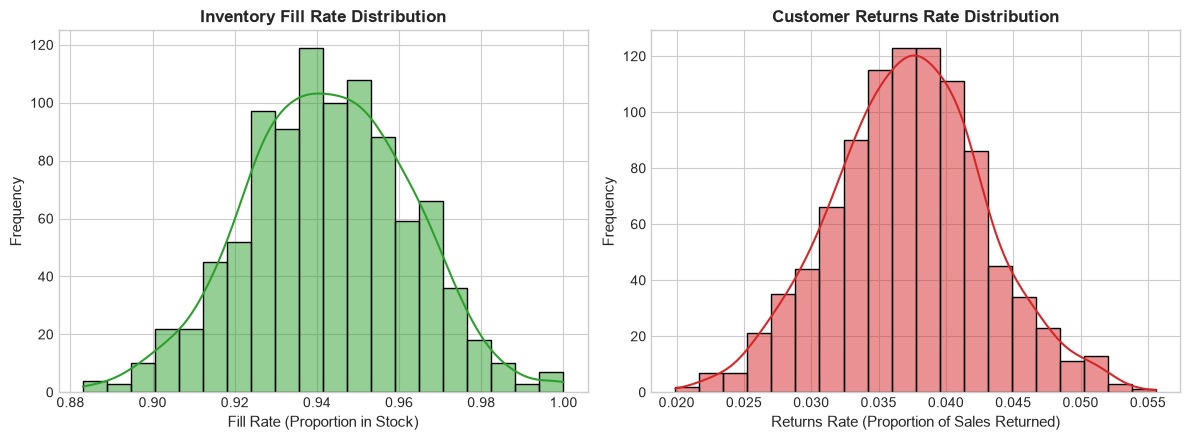

Inventory Fill Rate: Mean = 0.943, Min = 0.883, Max = 1.000
Returns Rate       : Mean = 0.0372, Min = 0.0199, Max = 0.0556
Correlation: inventory_fill_rate vs sales = -0.0640
Correlation: returns_rate vs sales        = 0.1954


In [12]:
# 5.6 Operational Diagnostics: Inventory Fill Rate & Returns Rate
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df['inventory_fill_rate'], bins=20, kde=True, color='#2ca02c', ax=ax1)
ax1.set_title('Inventory Fill Rate Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Fill Rate (Proportion in Stock)', fontsize=11)
ax1.set_ylabel('Frequency', fontsize=11)

sns.histplot(df['returns_rate'], bins=20, kde=True, color='#d62728', ax=ax2)
ax2.set_title('Customer Returns Rate Distribution', fontsize=12, fontweight='bold')
ax2.set_xlabel('Returns Rate (Proportion of Sales Returned)', fontsize=11)
ax2.set_ylabel('Frequency', fontsize=11)

plt.tight_layout()
plt.show()

print(f"Inventory Fill Rate: Mean = {df['inventory_fill_rate'].mean():.3f}, Min = {df['inventory_fill_rate'].min():.3f}, Max = {df['inventory_fill_rate'].max():.3f}")
print(f"Returns Rate       : Mean = {df['returns_rate'].mean():.4f}, Min = {df['returns_rate'].min():.4f}, Max = {df['returns_rate'].max():.4f}")
print(f"Correlation: inventory_fill_rate vs sales = {df['inventory_fill_rate'].corr(df['monthly_sales']):.4f}")
print(f"Correlation: returns_rate vs sales        = {df['returns_rate'].corr(df['monthly_sales']):.4f}")

## 6. Key Observations & Findings (from Synthetic Demonstration Data)

1. **Dataset Integrity & Preservation:**
   - Contains exactly 960 rows and 18 columns representing 40 stores over 24 calendar months (2023–2024).
   - Zero duplicate records.
   - Missing data is confined strictly to `ad_spend` (5 missing values / 0.52%); all other 17 columns are 100% complete.
   - **No raw values were modified**; the Store 6 January 2023 anomaly (1,000,000 visitors) is preserved intact in `data/raw/retail_sales_demo_data.csv`.
2. **Simulated Foot Traffic Correlation & Causation:**
   - When including the Store 6 anomaly, Pearson correlation is distorted to $r = 0.0535$.
   - When excluding this single 1M outlier, the synthetic model reflects a **strong positive linear correlation ($r = 0.5969$, $p < 0.001$)** between foot traffic and sales.
   - **Critical Note:** This correlation demonstrates co-occurrence within the synthetic model rules and **does not establish causation**.
3. **Simulated Holiday Seasonality Lift:**
   - In the synthetic dataset, simulated holiday months (November & December) deliver an average monthly revenue of **INR 3,897.96**, compared to **INR 3,213.04** during non-holiday months—reflecting a **+21.32% holiday revenue lift** encoded in the simulation.
4. **Synthetic Store Performance Disparities:**
   - Disparities across the 40 simulated stores: Store 37 generated **INR 127,214.07** over 24 months, whereas Store 7 generated **INR 47,367.90** (a 2.69x performance differential).
5. **Physical Store Area & Yield:**
   - Store footprint (`store_size_sqft`) exhibits a moderate positive correlation with sales ($r = 0.2730$), with an average sales yield of **0.125 INR per sq. ft.** in this synthetic model.
6. **Promotional Lift in Simulation:**
   - Incremental promotional days show higher average sales within the synthetic model, peaking around 5–6 promotion days per month.


## 7. Dataset Limitations & Day 4 Roadmap

### Limitations:
- **Synthetic Origin:** Dataset is synthetic demonstration data and does not represent physical in-store camera or GPS sensor records.
- **Missing Mobility Fields:**
  - Lacks geospatial coordinates (`latitude`, `longitude`) for map rendering and distance modeling.
  - Lacks hourly traffic granularity (`00:00 - 23:00`), capturing only monthly aggregate traffic.
  - Lacks customer dwell time (minutes spent inside store).
  - Lacks named geographic clusters (neighborhoods, commercial zones).

### Day 4 Roadmap:
1. **Design Synthetic Mobility Framework (Phase 2):**
   - Assign realistic Bengaluru retail corridor coordinates (`latitude`, `longitude`) to each of the 40 stores.
   - Map stores to recognized commercial micro-markets (Koramangala, Indiranagar, Whitefield, HSR Layout, Jayanagar).
2. **Simulate Intraday Mobility & Dwell Time:**
   - Model synthetic hourly footfall curves reflecting weekday evening spikes and weekend shopping surges.
   - Generate realistic dwell time distributions by store category.
3. **Data Integration & Preparation (Phase 3):**
   - Impute the 5 `ad_spend` missing values.
   - Join retail commercial records with hyper-local mobility records via `store_id`.
